# Fitting the defensive-shape model on 20 matches

Companion to `defensive_shape_integrity.ipynb`. That notebook studies one match with settings borrowed from the
pitch-control literature. This one uses **all 20 matches** to:

1. **Extract** the frames the model needs from every tracking file (pass releases, possession starts and ends).
2. **Fit the pitch-control settings**: reaction time, ball speeds, uncertainty, how much of a receiver's run to
   credit, … — by maximising how well $P_{succ}$ predicts whether each real pass was completed.
3. **Regress the value surface on pitch-control features**, so the value of a location depends on the defensive
   situation there, not only on where it is.

Results are written to `notebooks/fitted/`, which the main notebook loads automatically.

**Train / test split.** 15 matches are used for fitting; 5 are held out, including the case-study match
1925299, so every number the main notebook reports about that match is out-of-sample.

**Data.** Step 1 needs every match's tracking file (Git LFS): run `git lfs pull` in the repo first. If a file is
only an LFS pointer, the cell downloads it from GitHub instead and deletes it after extracting.

In [1]:
import hashlib, json, pickle, subprocess, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path.cwd()
while not (ROOT / "data" / "matches").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
DERIVED = DATA / "derived" / "frames"; DERIVED.mkdir(parents=True, exist_ok=True)
FITTED = ROOT / "notebooks" / "fitted"; FITTED.mkdir(parents=True, exist_ok=True)
MATCHES = sorted(p.name for p in (DATA / "matches").iterdir())
TEST = ["1925299", "1959846", "2006229", "2010085", "2006363"]
TRAIN = [m for m in MATCHES if m not in TEST]
REFIT = False        # True = re-run the (slow, ~1 h) settings fit instead of loading fitted/pitch_control_settings.json
print(len(MATCHES), "matches |", len(TRAIN), "train |", len(TEST), "test:", TEST)

20 matches | 15 train | 5 test: ['1925299', '1959846', '2006229', '2010085', '2006363']


## 1. Extract the frames the model needs
For each match: every possession's start and end frame, ±2 frames for the velocity. About 5,000 frames per match
instead of 60,000, saved to `data/derived/frames/<match>.parquet` (not committed — regenerate with this cell).

In [2]:
URL = "https://media.githubusercontent.com/media/misoverfitting/soccer_data/main/data/matches/{m}/{m}_tracking_extrapolated.jsonl"

def needed_frames(m):
    e = pd.read_csv(DATA / f"matches/{m}/{m}_dynamic_events.csv", low_memory=False, usecols=["event_type", "frame_start", "frame_end"])
    pp = e[e.event_type == "player_possession"]
    return {x + d for col in ("frame_start", "frame_end") for x in pp[col].dropna().astype(int) for d in (-2, 0, 2)}

def extract(m):
    out = DERIVED / f"{m}.parquet"
    if out.exists():
        return "cached"
    raw = DATA / f"matches/{m}/{m}_tracking_extrapolated.jsonl"; downloaded = False
    if raw.stat().st_size < 10_000:                      # an LFS pointer: fetch the real file
        ptr = dict(l.split(" ", 1) for l in raw.read_text().strip().splitlines())
        tmp = DERIVED / f"{m}.jsonl"
        subprocess.run(["curl", "-sS", "-L", "-o", str(tmp), URL.format(m=m)], check=True)
        assert hashlib.sha256(tmp.read_bytes()).hexdigest() == ptr["oid"].split(":")[1], "checksum mismatch"
        raw, downloaded = tmp, True
    need, rows = needed_frames(m), []
    with open(raw) as fh:
        for i, line in enumerate(fh):
            if i in need:
                r = json.loads(line)
                rows += [(r["frame"], p["player_id"], p["x"], p["y"], p["is_detected"]) for p in r["player_data"]]
                if r["ball_data"].get("x") is not None:
                    rows.append((r["frame"], -1, r["ball_data"]["x"], r["ball_data"]["y"], True))
    pd.DataFrame(rows, columns=["frame", "player_id", "x", "y", "is_detected"]).to_parquet(out, index=False)
    if downloaded:
        raw.unlink()
    return f"{len(need)} frames"

for m in MATCHES:
    print(m, extract(m))

1874553 cached
1886347 cached
1899585 cached
1925299 cached
1927964 cached
1953632 cached
1959846 cached
1986691 cached
1996435 cached
1996436 cached
2006229 cached
2006363 cached
2007448 cached
2007721 cached
2010085 cached
2011166 cached
2013725 cached
2015213 cached
2016236 cached
2017461 cached


## 2. Build the datasets
* **Passes** — every pass with a targeted passing option, at its release frame: all players' positions, velocities,
  top speed and acceleration, the ball, the intended receiver and their run (if any), and whether it was completed.
* **Possession starts** — every possession at its first frame, with SkillCorner's EPV, for the value regression.

In [3]:
NMAX = 24
PHYS_AGG = pd.read_csv(DATA / "aggregates" / "aus1league_physicalaggregates_20242025.csv") \
    .groupby("player_id")[["psv99", "timetosprint_top3"]].mean()

def load(m):
    meta = json.load(open(DATA / "matches" / m / f"{m}_match.json"))
    ev = pd.read_csv(DATA / "matches" / m / f"{m}_dynamic_events.csv", low_memory=False)
    pl = pd.DataFrame([{"player_id": p["id"], "team_id": p["team_id"], "gk": p["player_role"]["name"] == "Goalkeeper",
                        "group": p["player_role"]["position_group"]} for p in meta["players"]]).join(PHYS_AGG, on="player_id")
    for c in ["psv99", "timetosprint_top3"]:
        pl[c] = pl[c].fillna(pl.groupby("group")[c].transform("median")).fillna(PHYS_AGG[c].median())
    pl["vmax"] = pl.psv99 / 3.6; pl["amax"] = np.clip((25 / 3.6) / pl.timetosprint_top3, 3.0, 7.0)
    frames = {f: g.set_index("player_id") for f, g in pd.read_parquet(DERIVED / f"{m}.parquet").groupby("frame")}
    return ev, pl.set_index("player_id"), frames

def state(frames, pl, frame, att_team, att_side):
    """Same as frame_state in the main notebook."""
    if frame not in frames:
        return None
    flip = -1.0 if att_side == "right_to_left" else 1.0
    cur = frames[frame]; prv = frames.get(frame - 2, cur); nxt = frames.get(frame + 2, cur)
    ball = cur.loc[-1, ["x", "y"]].to_numpy(float) * flip if -1 in cur.index else None
    p = cur.drop(index=-1, errors="ignore"); p = p[p.index.isin(pl.index)]
    xy = p[["x", "y"]].to_numpy(float) * flip
    a = prv.reindex(p.index)[["x", "y"]].to_numpy(float) * flip; c = nxt.reindex(p.index)[["x", "y"]].to_numpy(float) * flip
    a = np.where(np.isnan(a), xy, a); c = np.where(np.isnan(c), xy, c)
    info = pl.loc[p.index]
    return {"pid": p.index.to_numpy(), "xy": xy, "v": (c - a) / 0.4, "att": (info.team_id == att_team).to_numpy(),
            "gk": info.gk.to_numpy(), "vmax": info.vmax.to_numpy(), "amax": info.amax.to_numpy(), "ball": ball}

def pad(s):
    n = min(len(s["pid"]), NMAX)
    out = {"xy": np.zeros((NMAX, 2)), "v": np.zeros((NMAX, 2)), "vmax": np.ones(NMAX), "amax": np.ones(NMAX),
           "att": np.zeros(NMAX, bool), "gk": np.zeros(NMAX, bool), "valid": np.zeros(NMAX, bool)}
    for k in ("xy", "v", "vmax", "amax", "att", "gk"):
        out[k][:n] = s[k][:n]
    out["valid"][:n] = True
    return out

P, S = [], []
for m in MATCHES:
    ev, pl, frames = load(m)
    po = ev[ev.event_type == "passing_option"]; runs = ev[ev.event_type == "off_ball_run"].set_index("event_id")
    tgt = po[po.targeted == True].drop_duplicates("associated_player_possession_event_id").set_index("associated_player_possession_event_id")
    for e in ev[ev.event_type == "player_possession"].sort_values("frame_start").itertuples():
        s0 = state(frames, pl, int(e.frame_start), e.team_id, e.attacking_side)
        if s0 is not None and s0["att"].sum() >= 7 and (~s0["att"]).sum() >= 7 and pd.notna(e.possession_epv_for_start):
            S.append({"m": m, **pad(s0), "c": np.array([e.x_start, e.y_start], float), "epv": e.possession_epv_for_start})
        if e.end_type != "pass" or e.event_id not in tgt.index:
            continue
        s = state(frames, pl, int(e.frame_end), e.team_id, e.attacking_side)
        if s is None or s["ball"] is None or s["att"].sum() < 7 or (~s["att"]).sum() < 7:
            continue
        o = tgt.loc[e.event_id]; r = np.where(s["pid"] == o.player_id)[0]
        if not len(r) or r[0] >= NMAX:
            continue
        r = r[0]; run_id = o.associated_off_ball_run_event_id
        method, end, t_left = 0, s["xy"][r], 0.0
        if pd.notna(run_id) and run_id in runs.index and runs.loc[run_id].frame_end > e.frame_end:
            method, end, t_left = 2, np.array([runs.loc[run_id].x_end, runs.loc[run_id].y_end], float), (runs.loc[run_id].frame_end - e.frame_end) / 10
        elif np.linalg.norm(s["v"][r]) > 2.0:
            method = 1
        P.append({"m": m, **pad(s), "ball": s["ball"], "r_idx": r, "r_xy": s["xy"][r], "r_v": s["v"][r], "r_method": method,
                  "r_run_end": end, "r_t_left": t_left, "completed": e.pass_outcome == "successful", "sc_xpass": o.xpass_completion})
stack = lambda rows: {k: np.array([r[k] for r in rows]) for k in rows[0]}
PASSES, STARTS = stack(P), stack(S)
print(f"{len(P):,} passes with a targeted option, {len(S):,} possession starts")

15,155 passes with a targeted option, 18,040 possession starts


## 3. The pitch-control model, batched
The same model as Sections 4 and 6 of the main notebook — arrival times, the race, interception, the lofted
option, the projected run — written to evaluate thousands of passes at once, with every setting an argument.
Two settings are new: **RUN_CREDIT** (how much of a receiver's projected run to credit: 1 = they arrive exactly
with the ball, 0 = they get no head start) and **ACC_SCALE** (a multiplier on every player's acceleration).

In [4]:
NAMES = ["T_REACT", "OMEGA", "V_BALL", "SIGMA", "TIE_BREAK", "V_LOFT", "T_HANG", "LOFT_CONTROL", "RUN_CREDIT", "ACC_SCALE"]
DEFAULTS = dict(T_REACT=0.5, OMEGA=2 * np.pi, V_BALL=15.0, SIGMA=0.45, TIE_BREAK=0.3, V_LOFT=12.0, T_HANG=0.6,
                LOFT_CONTROL=0.8, RUN_CREDIT=1.0, ACC_SCALE=1.0)
BOUNDS = [(0.1, 1.2), (np.pi / 2, 4 * np.pi), (10, 25), (0.15, 1.2), (0.0, 1.0), (8, 20), (0.2, 1.5), (0.4, 1.0), (0.0, 1.0), (0.5, 1.5)]
sig = lambda z: 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))

def facing_proxy(xy, v, ball):
    return np.where(np.linalg.norm(v, axis=2, keepdims=True) > 1.5, v, ball[:, None, :] - xy)

def time_to_reach_b(xy, v, vmax, amax, facing, targets, th):
    a = amax * th["ACC_SCALE"]; p_r = xy + v * th["T_REACT"]
    diff = targets[:, None, :, :] - p_r[:, :, None, :]; d = np.linalg.norm(diff, axis=3)
    vm, am = vmax[:, :, None], a[:, :, None]; d_acc = vm ** 2 / (2 * am)
    t = th["T_REACT"] + np.where(d < d_acc, np.sqrt(2 * d / am), vm / am + (d - d_acc) / vm)
    f = facing / (np.linalg.norm(facing, axis=2, keepdims=True) + 1e-9); u = diff / (d[..., None] + 1e-9)
    return t + np.where(d > 1.0, np.arccos(np.clip((u * f[:, :, None, :]).sum(3), -1, 1)) / th["OMEGA"], 0.0)

def project(D, th):
    p, v, ball, method, end, t_left = D["r_xy"], D["r_v"], D["ball"], D["r_method"], D["r_run_end"], np.maximum(D["r_t_left"], 0.1)
    def pos(t):
        run = p + (end - p) * np.minimum(1.0, t / t_left)[:, None]; vel = p + v * np.minimum(t, 2.0)[:, None]
        return np.where((method == 2)[:, None], run, np.where((method == 1)[:, None], vel, p))
    t = np.linalg.norm(p - ball, axis=1) / th["V_BALL"]
    for _ in range(8):
        t = np.linalg.norm(pos(t) - ball, axis=1) / th["V_BALL"]
    return pos(t), np.where(method > 0, t, np.nan)

def p_succ_b(D, th, target=None, use_receiver=True):
    k = np.pi / (np.sqrt(3) * th["SIGMA"])
    if target is None:
        target, t_arr = project(D, th)
    else:
        t_arr = np.full(len(target), np.nan)
    ball, xy, v, valid, att = D["ball"], D["xy"], D["v"], D["valid"], D["att"]
    fr = np.linspace(0.15, 0.9, 8)
    path = ball[:, None, :] + fr[None, :, None] * (target[:, None, :] - ball[:, None, :])
    T = time_to_reach_b(xy, v, D["vmax"], D["amax"], facing_proxy(xy, v, ball), np.concatenate([target[:, None], path], 1), th)
    T = np.where(valid[:, :, None], T, np.inf)
    if use_receiver:
        r, i = D["r_idx"], np.arange(len(D["r_idx"]))
        rt = t_arr + (1 - th["RUN_CREDIT"]) * np.maximum(0, T[i, r, 0] - np.nan_to_num(t_arr))
        T[i, r, 0] = np.where(np.isnan(t_arr), T[i, r, 0], np.minimum(T[i, r, 0], rt))
    Tt = T[:, :, 0]
    t_att = np.where(att, Tt, np.inf).min(1); t_def = np.where(~att & valid, Tt, np.inf).min(1)
    d_ball = np.linalg.norm(target - ball, axis=1); tb = d_ball / th["V_BALL"]
    eff = lambda t, b: np.maximum(t, b) + th["TIE_BREAK"] * t
    p_att = sig(k * (eff(t_def, tb) - eff(t_att, tb)))
    Tp = np.where((~att & valid)[:, :, None], T[:, :, 1:], np.inf).min(1)
    d_path = np.linalg.norm(path - ball[:, None, :], axis=2)
    p_int = (sig(k * (d_path / th["V_BALL"] - Tp)) * (d_path > 2.0)).max(1)
    tl = d_ball / th["V_LOFT"] + th["T_HANG"]
    p_loft = np.where(d_ball > 15.0, th["LOFT_CONTROL"] * sig(k * (eff(t_def, tl) - eff(t_att, tl))), 0.0)
    return np.maximum((1 - p_int) * p_att, p_loft)

is_test = np.isin(PASSES["m"], TEST); y = PASSES["completed"].astype(float)
TR = {k: v[~is_test] for k, v in PASSES.items()}; TE = {k: v[is_test] for k, v in PASSES.items()}
print("sanity check — match 1925299 with default settings, AUC (should be 0.861):",
      round(roc_auc_score(PASSES["completed"][PASSES["m"] == "1925299"],
                          p_succ_b({k: v[PASSES["m"] == "1925299"] for k, v in PASSES.items()}, DEFAULTS)), 3))

sanity check — match 1925299 with default settings, AUC (should be 0.861): 0.861


## 4. Fit the settings
Minimise the log-loss (the negative log-likelihood) of real pass outcomes on the 15 training matches, with
Powell's method inside sensible bounds, from two starting points. ~1 hour; set `REFIT = True` to re-run it,
otherwise the saved result is loaded.

In [5]:
SET_FILE = FITTED / "pitch_control_settings.json"
def nll(x, D=TR, yv=y[~is_test]):
    p = np.clip(p_succ_b(D, dict(zip(NAMES, x))), 1e-4, 1 - 1e-4)
    return -np.mean(yv * np.log(p) + (1 - yv) * np.log(1 - p))

if REFIT or not SET_FILE.exists():
    x0 = np.array([DEFAULTS[n] for n in NAMES]); best = None
    for start in [x0, x0 * np.array([1.2, 1, 1.1, 1.3, 0.5, 1, 1, 1, 0.6, 1])]:
        start = np.clip(start, [b[0] for b in BOUNDS], [b[1] for b in BOUNDS])
        r = minimize(nll, start, method="Powell", bounds=BOUNDS, options={"maxiter": 40, "xtol": 1e-3, "ftol": 1e-5})
        best = r if best is None or r.fun < best.fun else best
    FIT = dict(zip(NAMES, map(float, best.x)))
else:
    FIT = json.load(open(SET_FILE))["settings"]
pd.DataFrame({"default": DEFAULTS, "fitted": FIT}).round(3)

,default,fitted
T_REACT,0.500,0.105
OMEGA,6.283,12.538
V_BALL,15.000,17.275
SIGMA,0.450,0.618
TIE_BREAK,0.300,0.063
V_LOFT,12.000,19.964
T_HANG,0.600,0.510
LOFT_CONTROL,0.800,0.725
RUN_CREDIT,1.000,0.543
ACC_SCALE,1.000,0.940


In [6]:
def scores(D, yv, th):
    p = np.clip(p_succ_b(D, th), 1e-4, 1 - 1e-4)
    return {"AUC": roc_auc_score(yv, p), "log-loss": log_loss(yv, p), "Brier": brier_score_loss(yv, p)}, p
rows = {}
for lab, th in [("default", DEFAULTS), ("fitted", FIT)]:
    rows[f"{lab} · train"] = scores(TR, y[~is_test], th)[0]
    rows[f"{lab} · test"] = scores(TE, y[is_test], th)[0]
sc = TE["sc_xpass"].astype(float); ok = ~np.isnan(sc)
rows["SkillCorner · test"] = {"AUC": roc_auc_score(y[is_test][ok], sc[ok]), "log-loss": log_loss(y[is_test][ok], np.clip(sc[ok], 1e-4, 1 - 1e-4)),
                              "Brier": brier_score_loss(y[is_test][ok], sc[ok])}
SCORES = pd.DataFrame(rows).T
SCORES.round(3)

,AUC,log-loss,Brier
default · train,0.849,0.410,0.105
default · test,0.850,0.396,0.099
fitted · train,0.883,0.279,0.085
fitted · test,0.885,0.268,0.081
SkillCorner · test,0.910,0.246,0.078


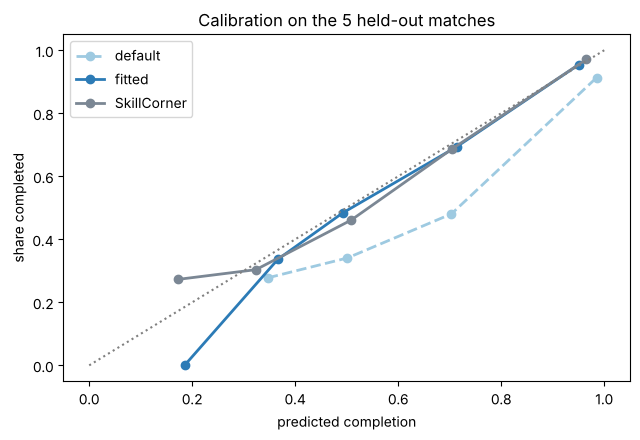

saved notebooks/fitted/pitch_control_settings.json


In [7]:
bins = np.linspace(0, 1, 6); CALIB = {}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for lab, p, col, ls in [("default", scores(TE, y[is_test], DEFAULTS)[1], "#9ecae1", "--"),
                        ("fitted", scores(TE, y[is_test], FIT)[1], "#2c7bb6", "-"),
                        ("SkillCorner", np.where(ok, sc, np.nan), "#7b8794", "-")]:
    msk = ~np.isnan(p); idx = np.clip(np.digitize(p[msk], bins) - 1, 0, 4)
    CALIB[lab] = [{"pred": float(p[msk][idx == b].mean()), "actual": float(y[is_test][msk][idx == b].mean()),
                   "n": int((idx == b).sum())} for b in range(5) if (idx == b).any()]
    ax.plot([c["pred"] for c in CALIB[lab]], [c["actual"] for c in CALIB[lab]], "o", ls=ls, c=col, lw=2, label=lab)
ax.plot([0, 1], [0, 1], ":", c="grey"); ax.set_xlabel("predicted completion"); ax.set_ylabel("share completed")
ax.set_title("Calibration on the 5 held-out matches"); ax.legend(); plt.tight_layout(); plt.show()

json.dump({"settings": FIT, "defaults": DEFAULTS, "train_matches": TRAIN, "test_matches": TEST,
           "scores": SCORES.reset_index(names="set").to_dict("records"), "calibration_test": CALIB,
           "n_train": int((~is_test).sum()), "n_test": int(is_test.sum())}, open(SET_FILE, "w"), indent=2)
print("saved", SET_FILE.relative_to(ROOT))

## 5. Regress V on pitch-control features

The value surface $V(x, y)$ only knows **where** the ball is. Two receivers on the same spot — one unmarked, one
with a defender on his back — get the same value. That makes the gain map, the threat available and the option
ranking blind to the defensive situation at the target, which is exactly what the research is about.

So we model SkillCorner's EPV at the start of each possession as the location value times a multiplier that
depends on the defensive situation at that spot:

$$\log \text{EPV} = \log V_{loc}(x, y) + b_0 + \textbf{b} \cdot \textbf{f}$$

with three features, each also interacted with closeness to goal ($e^{-d_{goal}/25}$), because pressure matters
more near goal:

* **pressure time** — how soon the nearest defender can get there (s, from the fitted model)
* **nearest defender** — distance to the nearest defender (log of metres)
* **defenders ahead** — defenders between the spot and goal, inside a 30° cone

$V_{loc}$ is rebuilt from the training matches only. A gradient-boosting model on the same inputs gives a
ceiling: how much of the signal the simple, interpretable version captures.

In [8]:
HALF_L, HALF_W = 52.5, 34.0
GRID_X = np.arange(-HALF_L + 0.5, HALF_L, 1.0); GRID_Y = np.arange(-HALF_W + 0.5, HALF_W, 1.0)
GX, GY = np.meshgrid(GRID_X, GRID_Y)

def value_surface(x, y_, epv, bin_m=3.0, smooth=2.5, k=5.0):
    xb = np.arange(-HALF_L, HALF_L + bin_m, bin_m); yb = np.arange(-HALF_W, HALF_W + bin_m, bin_m)
    s, _, _ = np.histogram2d(x, y_, [xb, yb], weights=epv); n, _, _ = np.histogram2d(x, y_, [xb, yb])
    m = gaussian_filter((s + k * np.median(epv)) / (n + k), smooth, mode="nearest")
    f = RegularGridInterpolator(((xb[:-1] + xb[1:]) / 2, (yb[:-1] + yb[1:]) / 2), m, bounds_error=False, fill_value=None)
    return f(np.column_stack([GX.ravel(), GY.ravel()])).reshape(GX.shape)

def lookup(grid, xy):
    ix = np.clip(np.round(xy[..., 0] + HALF_L - 0.5).astype(int), 0, len(GRID_X) - 1)
    iy = np.clip(np.round(xy[..., 1] + HALF_W - 0.5).astype(int), 0, len(GRID_Y) - 1)
    return grid[iy, ix]

def features(D, c, th):
    xy, v, valid, att = D["xy"], D["v"], D["valid"], D["att"]; defn = ~att & valid
    T = time_to_reach_b(xy, v, D["vmax"], D["amax"], facing_proxy(xy, v, c), c[:, None, :], th)[:, :, 0]
    pressure = np.clip(np.where(defn, T, np.inf).min(1), 0, 4)
    nearest = np.clip(np.where(defn, np.linalg.norm(xy - c[:, None], axis=2), np.inf).min(1), 0, 20)
    goal = np.array([HALF_L, 0.0]); to_goal = goal - c; to_def = xy - c[:, None, :]
    cosang = (to_def * to_goal[:, None]).sum(2) / (np.linalg.norm(to_def, axis=2) * np.linalg.norm(to_goal, axis=1)[:, None] + 1e-9)
    closer = np.linalg.norm(xy - goal, axis=2) < np.linalg.norm(to_goal, axis=1)[:, None]
    ahead = (defn & (cosang > np.cos(np.radians(30))) & closer).sum(1)
    return np.column_stack([pressure, np.log1p(nearest), ahead])

c = STARTS["c"]; F = features(STARTS, c, FIT); epv = STARTS["epv"].astype(float)
ok_ = (epv > 0) & np.isfinite(F).all(1); s_test = np.isin(STARTS["m"], TEST)
tr, te = ok_ & ~s_test, ok_ & s_test
V_loc = value_surface(c[tr, 0], c[tr, 1], epv[tr]); base = lookup(V_loc, c)
close = np.exp(-np.linalg.norm(np.array([HALF_L, 0]) - c, axis=1) / 25.0)
X = np.column_stack([F, F * close[:, None]])
FEAT = ["pressure_time", "log1p_nearest_def_m", "defenders_ahead",
        "pressure_time×near_goal", "log1p_nearest_def_m×near_goal", "defenders_ahead×near_goal"]
beta, *_ = np.linalg.lstsq(np.column_stack([np.ones(tr.sum()), X[tr]]), np.log(epv[tr]) - np.log(base[tr]), rcond=None)
pred_ctx = base * np.exp(np.column_stack([np.ones(len(X)), X]) @ beta)
gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05).fit(np.column_stack([c, F])[tr], np.log(epv[tr]))
pred_gbm = np.exp(gbm.predict(np.column_stack([c, F])))
r2 = lambda p, msk: 1 - ((np.log(epv[msk]) - np.log(p[msk])) ** 2).sum() / ((np.log(epv[msk]) - np.log(epv[msk]).mean()) ** 2).sum()
VRES = pd.DataFrame([{"model": lab, "test R² (log EPV)": r2(p, te), "test Spearman ρ": spearmanr(p[te], epv[te]).statistic}
                     for lab, p in [("location only", base), ("location + pitch-control features", pred_ctx),
                                    ("gradient boosting (ceiling)", pred_gbm)]])
print("coefficients:", dict(zip(["intercept"] + FEAT, np.round(beta, 3))))
VRES.round(3)

coefficients: {'intercept': np.float64(-0.086), 'pressure_time': np.float64(-0.03), 'log1p_nearest_def_m': np.float64(0.047), 'defenders_ahead': np.float64(-0.013), 'pressure_time×near_goal': np.float64(1.536), 'log1p_nearest_def_m×near_goal': np.float64(-0.639), 'defenders_ahead×near_goal': np.float64(-0.093)}


,model,test R² (log EPV),test Spearman ρ
0,location only,0.705,0.890
1,location + pitch-control features,0.795,0.905
2,gradient boosting (ceiling),0.821,0.910


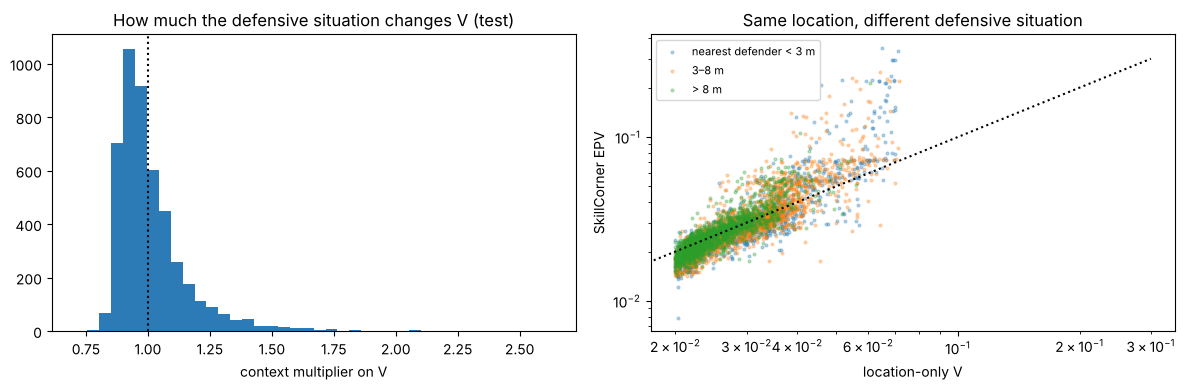

saved notebooks/fitted/value_model.json


In [9]:
mult = pred_ctx[te] / base[te]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(mult, bins=40, color="#2c7bb6"); axes[0].axvline(1, c="k", ls=":")
axes[0].set_xlabel("context multiplier on V"); axes[0].set_title("How much the defensive situation changes V (test)")
for lab, msk_ in [("nearest defender < 3 m", F[:, 1] < np.log1p(3)), ("3–8 m", (F[:, 1] >= np.log1p(3)) & (F[:, 1] < np.log1p(8))),
                  ("> 8 m", F[:, 1] >= np.log1p(8))]:
    sel = te & msk_
    axes[1].scatter(base[sel], epv[sel], s=4, alpha=0.3, label=lab)
axes[1].plot([0, 0.3], [0, 0.3], "k:"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("location-only V"); axes[1].set_ylabel("SkillCorner EPV"); axes[1].legend(fontsize=8)
axes[1].set_title("Same location, different defensive situation"); plt.tight_layout(); plt.show()

json.dump({"grid_x0": float(GRID_X[0]), "grid_y0": float(GRID_Y[0]), "V_loc": V_loc.round(6).tolist(),
           "intercept": float(beta[0]), "coef": dict(zip(FEAT, map(float, beta[1:]))), "near_goal_scale_m": 25.0,
           "cone_deg": 30.0, "nearest_cap_m": 20.0, "pressure_cap_s": 4.0, "results": VRES.to_dict("records"),
           "n_train": int(tr.sum()), "n_test": int(te.sum()), "test_matches": TEST}, open(FITTED / "value_model.json", "w"))
print("saved", (FITTED / "value_model.json").relative_to(ROOT))